# 04 — Neural Network Experiments

## 1. Research Objectives and Experimental Scope

This notebook evaluates two neural-network architectures for supervised multi-class topic classification using the 20 Newsgroups dataset.

The experiments investigate:

- **EXP-04 — TextCNN:** a convolutional neural network that learns word embeddings and identifies local patterns in sequences of text.
- **EXP-05 — Bidirectional LSTM:** a recurrent neural network that processes text in both forward and backward directions to capture contextual information.

The objective is to establish neural-network baselines and examine how convolutional and recurrent architectures compare in predictive performance, learning behaviour and computational cost.

Both models use the same message-body representation, vocabulary constraints, training and validation partitions, and primary evaluation metric. Their architecture-specific parameters are configured separately.

The vocabulary is constructed exclusively from training documents. Both models learn their word embeddings from the available training data rather than using externally pretrained embeddings.

The experiments use bounded configurations and a CPU-based environment. They are intended to provide a controlled comparison of two neural architectures, not an exhaustive search for optimal hyperparameters.

The official test partition remains reserved for the final evaluation stage. It is not used for vocabulary construction, model training, checkpoint selection or validation-based decisions.

The reusable implementation is maintained in `src/topicsense/`, with experiment settings defined in `configs/neural_networks.yaml`.

In [1]:
import json
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import yaml

from topicsense.training.neural import run_neural_experiments

## 2. Experimental Configuration

The experiment configuration is maintained in `configs/neural_networks.yaml`. It centralises the dataset locations, preprocessing representation, vocabulary constraints, training parameters and output destinations.

Keeping these settings outside the notebook separates experiment configuration from implementation. It also allows the training procedure to be reused through both the notebook and the project's command-line interface.

The configuration summary below records the principal settings used in the experiments. Both architectures share the general training conditions, while their architecture-specific parameters are defined separately.

In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

CONFIG_PATH = PROJECT_ROOT / "configs" / "neural_networks.yaml"

if not CONFIG_PATH.is_file():
    raise FileNotFoundError(f"Configuration file not found: {CONFIG_PATH}")

with CONFIG_PATH.open("r", encoding="utf-8") as file:
    CONFIG = yaml.safe_load(file)

if not isinstance(CONFIG, dict):
    raise ValueError("The neural-network configuration must be a YAML mapping.")

print(f"Project root: {PROJECT_ROOT}")
print(f"Configuration: {CONFIG_PATH}")

configuration_summary = pd.Series(
    {
        "Dataset": "20 Newsgroups",
        "Representation": CONFIG["preprocessing"]["representation"],
        "Maximum vocabulary": CONFIG["vocabulary"]["max_size"],
        "Minimum token frequency": CONFIG["vocabulary"]["min_frequency"],
        "Maximum sequence length": CONFIG["training"]["max_sequence_length"],
        "Batch size": CONFIG["training"]["batch_size"],
        "Maximum epochs": CONFIG["training"]["epochs"],
        "Early-stopping patience": CONFIG["training"]["patience"],
        "Random seed": CONFIG["project"]["random_seed"],
        "Device": "CPU",
    },
    name="Configured value",
)

display(configuration_summary.to_frame())

Project root: /home/nkululekocyrilcele/projects/topicsense-nlp
Configuration: /home/nkululekocyrilcele/projects/topicsense-nlp/configs/neural_networks.yaml


,Configured value
Dataset,20 Newsgroups
Representation,message_body
Maximum vocabulary,30000
Minimum token frequency,2
Maximum sequence length,256
Batch size,64
Maximum epochs,25
Early-stopping patience,3
Random seed,42
Device,CPU


### Interpreting the Experimental Configuration

Both models use the message-body representation, a maximum vocabulary of 30,000 tokens, a minimum token frequency of two and a maximum sequence length of 256 tokens. The batch size is 64, and training is limited to 25 epochs with early-stopping patience set to three.

The fixed random seed supports reproducibility, while CPU execution reflects the computational environment used for these experiments.

These shared settings provide a consistent foundation for comparing the architectures. Their internal configurations are examined separately in Section 4.

## 3. Training and Validation Data

Both experiments use the existing training and validation partitions generated during the preprocessing stage.

The split was produced using a group-aware strategy that considers identified duplicate relationships. This reduces the risk of closely related documents appearing in both partitions and producing an overly optimistic assessment of model performance.

The training and validation identifiers are checked before either experiment begins. In particular, both partitions must be non-empty and must not share document identifiers.

Only records belonging to the official training partition are used to construct these development subsets. The official test partition remains separate and is reserved for the final assessment of the selected models.

In [3]:
SPLIT_PATH = PROJECT_ROOT / CONFIG["data"]["split_manifest_path"]

if not SPLIT_PATH.is_file():
    raise FileNotFoundError(SPLIT_PATH)

with SPLIT_PATH.open("r", encoding="utf-8") as file:
    SPLIT_MANIFEST = json.load(file)

TRAINING_IDS = set(SPLIT_MANIFEST["training_record_ids"])
VALIDATION_IDS = set(SPLIT_MANIFEST["validation_record_ids"])

assert TRAINING_IDS
assert VALIDATION_IDS
assert TRAINING_IDS.isdisjoint(VALIDATION_IDS)

split_summary = pd.Series(
    {
        "Training documents": len(TRAINING_IDS),
        "Validation documents": len(VALIDATION_IDS),
        "Training-validation overlap": len(TRAINING_IDS & VALIDATION_IDS),
        "Split method": SPLIT_MANIFEST.get(
            "method",
            "Not recorded",
        ),
        "Random seed": SPLIT_MANIFEST.get(
            "random_seed",
            "Not recorded",
        ),
    },
    name="Value",
)

display(split_summary.to_frame())

,Value
Training documents,9051
Validation documents,2263
Training-validation overlap,0
Split method,StratifiedGroupKFold over duplicate-connected ...
Random seed,42


### Interpreting the Development Split

The development partition contains 9,051 training documents and 2,263 validation documents. The identifier overlap is zero, confirming that no document has been assigned to both partitions.

The recorded splitting method is StratifiedGroupKFold, applied to groups connected through the identified duplicate relationships. This is important because closely related documents appearing in both training and validation data could make model performance appear stronger than it would be on genuinely unseen documents.

The validation partition is therefore used to assess generalisation during development, while the official test partition remains reserved for the final evaluation.

## 4. Neural-Network Architectures and Experimental Settings

The two architectures use the same dataset, message-body representation, vocabulary constraints, maximum sequence length, random seed, optimiser settings and validation-based checkpoint-selection procedure.

Their architecture-specific parameters are configured separately, allowing the comparison to focus on the differences between convolutional and recurrent approaches.

### EXP-04: TextCNN

TextCNN applies one-dimensional convolution filters to embedded token sequences. Different filter widths allow the network to identify local textual patterns across different sequence lengths. Max pooling reduces the resulting feature maps to a fixed-size representation, which is passed to the classification layer.

### EXP-05: Bidirectional LSTM

The Bidirectional LSTM processes each token sequence in both forward and backward directions. The resulting representations are combined to form a document representation for classification.

Packed sequences are used to prevent trailing padding tokens from contributing to recurrent computation.

Both models are configured for a maximum of 25 epochs, with early stopping after three consecutive epochs without an improvement in validation macro F1. The checkpoint with the highest validation macro F1 is selected for the reported validation metrics.

This common selection criterion provides a consistent basis for comparing the two models.

In [4]:
TEXTCNN_CONFIG = deepcopy(CONFIG)

TEXTCNN_CONFIG["model"] = {
    "architecture": "textcnn",
    "embedding_dim": 64,
    "num_filters": 64,
    "kernel_sizes": [3, 4, 5],
    "dropout": 0.5,
}

TEXTCNN_CONFIG["outputs"]["metrics_csv"] = "results/metrics/neural_textcnn.csv"
TEXTCNN_CONFIG["outputs"]["results_json"] = "results/logs/neural_textcnn.json"

BILSTM_CONFIG = deepcopy(CONFIG)

BILSTM_CONFIG["model"] = {
    "architecture": "bilstm",
    "embedding_dim": CONFIG["bilstm"]["embedding_dim"],
    "hidden_size": CONFIG["bilstm"]["hidden_size"],
    "num_layers": CONFIG["bilstm"]["num_layers"],
    "dropout": CONFIG["bilstm"]["dropout"],
}

BILSTM_CONFIG["outputs"]["metrics_csv"] = "results/metrics/neural_bilstm.csv"
BILSTM_CONFIG["outputs"]["results_json"] = "results/logs/neural_bilstm.json"

experiment_configuration = pd.DataFrame(
    [
        {
            "experiment_id": "EXP-04",
            "model": "TextCNN",
            "embedding_dimension": (TEXTCNN_CONFIG["model"]["embedding_dim"]),
            "architecture_parameters": ("64 filters; kernels 3, 4, 5"),
            "dropout": TEXTCNN_CONFIG["model"]["dropout"],
            "maximum_epochs": (TEXTCNN_CONFIG["training"]["epochs"]),
        },
        {
            "experiment_id": "EXP-05",
            "model": "BiLSTM",
            "embedding_dimension": (BILSTM_CONFIG["model"]["embedding_dim"]),
            "architecture_parameters": ("64 hidden units; 1 bidirectional layer"),
            "dropout": BILSTM_CONFIG["model"]["dropout"],
            "maximum_epochs": (BILSTM_CONFIG["training"]["epochs"]),
        },
    ]
)

display(experiment_configuration)

,experiment_id,model,embedding_dimension,architecture_parameters,dropout,maximum_epochs
0,EXP-04,TextCNN,64,"64 filters; kernels 3, 4, 5",0.5,25
1,EXP-05,BiLSTM,64,64 hidden units; 1 bidirectional layer,0.3,25


### Interpreting the Architecture Configurations

Both experiments use an embedding dimension of 64 and a maximum of 25 training epochs.

TextCNN uses 64 convolution filters with kernel sizes of 3, 4 and 5, allowing it to learn local patterns across different token-window lengths. Its dropout rate is 0.5.

BiLSTM uses a bidirectional recurrent layer with 64 hidden units and a dropout rate of 0.3. Its recurrent structure allows information from both directions of a sequence to contribute to the document representation.

Although the models share the main training conditions, their internal architectures differ considerably. The experiments therefore provide a comparison of these two approaches under the same data and evaluation protocol.

## 5. EXP-04: TextCNN Training and Validation

The first experiment evaluates the convolutional neural network.

During training, the model updates its parameters using the training documents. At the end of each epoch, its performance is assessed on the separate validation partition.

Validation macro F1 determines which checkpoint is retained. Training may stop before the maximum of 25 epochs if the metric fails to improve for the configured patience period.

The reported results therefore correspond to the best validation checkpoint, rather than automatically using the parameters from the final training epoch.

The recorded training output shows the progression of the experiment, including training loss, validation macro F1 and the selected checkpoint.

In [5]:
TEXTCNN_RESULTS = run_neural_experiments(
    TEXTCNN_CONFIG,
    project_root=PROJECT_ROOT,
)

assert len(TEXTCNN_RESULTS["runs"]) == 1

TEXTCNN_RUN = TEXTCNN_RESULTS["runs"][0]

assert TEXTCNN_RUN["experiment_id"] == "EXP-04"
assert TEXTCNN_RUN["model"] == "TextCNN"

print("TextCNN training and validation completed.")
print(f"Run ID: {TEXTCNN_RUN['run_id']}")
print(f"Best epoch: {TEXTCNN_RUN['best_epoch']}")
print(f"Validation macro F1: {TEXTCNN_RUN['metrics']['macro_f1']:.4f}")
print(f"Metrics: {TEXTCNN_RESULTS['metrics_csv']}")
print(f"Detailed results: {TEXTCNN_RESULTS['results_json']}")

Epoch 1/25 | loss=3.1972 | validation_macro_f1=0.1271
Epoch 2/25 | loss=2.9182 | validation_macro_f1=0.2199
Epoch 3/25 | loss=2.6955 | validation_macro_f1=0.3886
Epoch 4/25 | loss=2.4337 | validation_macro_f1=0.4880
Epoch 5/25 | loss=2.1994 | validation_macro_f1=0.5078
Epoch 6/25 | loss=1.9882 | validation_macro_f1=0.5425
Epoch 7/25 | loss=1.7874 | validation_macro_f1=0.6093
Epoch 8/25 | loss=1.6013 | validation_macro_f1=0.6314
Epoch 9/25 | loss=1.4421 | validation_macro_f1=0.6558
Epoch 10/25 | loss=1.2713 | validation_macro_f1=0.6693
Epoch 11/25 | loss=1.1175 | validation_macro_f1=0.6974
Epoch 12/25 | loss=0.9897 | validation_macro_f1=0.7076
Epoch 13/25 | loss=0.8577 | validation_macro_f1=0.7399
Epoch 14/25 | loss=0.7484 | validation_macro_f1=0.7398
Epoch 15/25 | loss=0.6558 | validation_macro_f1=0.7482
Epoch 16/25 | loss=0.5656 | validation_macro_f1=0.7498
Epoch 17/25 | loss=0.4996 | validation_macro_f1=0.7591
Epoch 18/25 | loss=0.4446 | validation_macro_f1=0.7647
Epoch 19/25 | loss=

### Interpreting the TextCNN Training Results

TextCNN achieved its highest validation macro F1 of **0.7774 at epoch 22**.

The validation macro F1 increased from 0.1271 in the first epoch to 0.7774 at the selected checkpoint. This indicates that the model progressively learned useful patterns for distinguishing the topic categories.

Training continued for three additional epochs without improving on the epoch-22 validation score. Early stopping therefore terminated the experiment after epoch 25, while retaining the checkpoint from epoch 22.

The result establishes TextCNN as a neural-network baseline. Its performance must also be considered alongside the BiLSTM comparison, class-level results and computational measurements reported later in this notebook.

## 6. EXP-05: Bidirectional LSTM Training and Validation

The second experiment evaluates the Bidirectional LSTM using the same training and validation document identifiers as TextCNN.

Unlike the convolutional architecture, the recurrent model processes the sequence in both directions. This allows its representation to incorporate information from preceding and following tokens.

The same early-stopping and checkpoint-selection procedure is applied. This ensures that differences in the reported results are not caused by using different validation criteria.

The training output records the model's progress across epochs and identifies the checkpoint that achieved the highest validation macro F1.

In [6]:
BILSTM_RESULTS = run_neural_experiments(
    BILSTM_CONFIG,
    project_root=PROJECT_ROOT,
)

assert len(BILSTM_RESULTS["runs"]) == 1

BILSTM_RUN = BILSTM_RESULTS["runs"][0]

assert BILSTM_RUN["experiment_id"] == "EXP-05"
assert BILSTM_RUN["model"] == "BiLSTM"

print("BiLSTM training and validation completed.")
print(f"Run ID: {BILSTM_RUN['run_id']}")
print(f"Best epoch: {BILSTM_RUN['best_epoch']}")
print(f"Validation macro F1: {BILSTM_RUN['metrics']['macro_f1']:.4f}")
print(f"Metrics: {BILSTM_RESULTS['metrics_csv']}")
print(f"Detailed results: {BILSTM_RESULTS['results_json']}")

Epoch 1/25 | loss=2.9231 | validation_macro_f1=0.1279
Epoch 2/25 | loss=2.6707 | validation_macro_f1=0.1730
Epoch 3/25 | loss=2.3902 | validation_macro_f1=0.2513
Epoch 4/25 | loss=2.1033 | validation_macro_f1=0.2634
Epoch 5/25 | loss=1.8711 | validation_macro_f1=0.3279
Epoch 6/25 | loss=1.6585 | validation_macro_f1=0.3700
Epoch 7/25 | loss=1.4768 | validation_macro_f1=0.3918
Epoch 8/25 | loss=1.2981 | validation_macro_f1=0.4168
Epoch 9/25 | loss=1.1348 | validation_macro_f1=0.4466
Epoch 10/25 | loss=0.9918 | validation_macro_f1=0.4350
Epoch 11/25 | loss=0.8604 | validation_macro_f1=0.4817
Epoch 12/25 | loss=0.7462 | validation_macro_f1=0.4906
Epoch 13/25 | loss=0.6365 | validation_macro_f1=0.5027
Epoch 14/25 | loss=0.5499 | validation_macro_f1=0.5198
Epoch 15/25 | loss=0.4618 | validation_macro_f1=0.5144
Epoch 16/25 | loss=0.3927 | validation_macro_f1=0.5204
Epoch 17/25 | loss=0.3304 | validation_macro_f1=0.5139
Epoch 18/25 | loss=0.2875 | validation_macro_f1=0.5233
Epoch 19/25 | loss=

### Interpreting the Bidirectional LSTM Training Results

The Bidirectional LSTM achieved its highest validation macro F1 of **0.5465 at epoch 19**.

Validation performance generally improved during training, although the progression was less consistent than that observed for TextCNN. After epoch 19, subsequent epochs did not produce a higher validation macro F1. The early-stopping condition was reached after epoch 22.

The model's selected checkpoint is therefore retained from epoch 19 rather than from the final completed epoch.

This experiment establishes a recurrent neural-network baseline. Its results can now be compared directly with those of TextCNN under the shared development and evaluation conditions.

## 7. Aggregate Validation Performance

The aggregate results provide the principal comparison between the two neural-network architectures.

Macro F1 is the primary evaluation metric because it gives equal importance to each topic category, regardless of how many validation documents belong to that category. Accuracy, macro precision, macro recall and weighted F1 provide additional perspectives on overall classification performance.

The table also records the number of documents used, vocabulary size and selected checkpoint epoch. These details help establish that the models were evaluated under comparable conditions.

All reported classification metrics are calculated on the validation partition. They must not be interpreted as final test-set performance.

In [7]:
NEURAL_RUNS = [TEXTCNN_RUN, BILSTM_RUN]

NEURAL_SUMMARY = pd.DataFrame(
    [
        {
            "experiment_id": run["experiment_id"],
            "model": run["model"],
            "training_documents": run["training_documents"],
            "validation_documents": run["validation_documents"],
            "vocabulary_size": run["vocabulary_size"],
            "best_epoch": run["best_epoch"],
            "accuracy": run["metrics"]["accuracy"],
            "macro_precision": run["metrics"]["macro_precision"],
            "macro_recall": run["metrics"]["macro_recall"],
            "macro_f1": run["metrics"]["macro_f1"],
            "weighted_f1": run["metrics"]["weighted_f1"],
        }
        for run in NEURAL_RUNS
    ]
)

display(
    NEURAL_SUMMARY.sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

,experiment_id,model,training_documents,validation_documents,vocabulary_size,best_epoch,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,EXP-04,TextCNN,9051,2263,30000,22,0.7795,0.7814,0.7758,0.7774,0.7793
1,EXP-05,BiLSTM,9051,2263,30000,19,0.5444,0.5532,0.5453,0.5465,0.5458


### Interpreting Aggregate Performance

TextCNN achieved the stronger validation results across all five reported classification metrics.

| Metric | TextCNN | BiLSTM |
|---|---:|---:|
| Accuracy | 0.7795 | 0.5444 |
| Macro precision | 0.7814 | 0.5532 |
| Macro recall | 0.7758 | 0.5453 |
| Macro F1 | **0.7774** | 0.5465 |
| Weighted F1 | 0.7793 | 0.5458 |

TextCNN's macro F1 exceeds that of BiLSTM by approximately 0.231. Its accuracy is also substantially higher, indicating that the performance difference is not limited to the equal-weighted class measure.

The close relationship between TextCNN's macro and weighted F1 suggests that its overall performance is reasonably consistent across the two averaging approaches. BiLSTM also shows relatively close macro and weighted scores, although at a considerably lower level.

Both experiments used 9,051 training documents, 2,263 validation documents and a vocabulary of 30,000 tokens. The comparison therefore reflects the different model configurations rather than differences in the number of documents or vocabulary size.

These findings favour TextCNN within the current experimental setup. They do not yet establish how either model performs on the reserved test partition.

## 8. Training History

The training histories provide insight into how the models learned over successive epochs.

Training loss measures how well each model fits the training documents. Validation accuracy and macro F1 indicate how effectively the learned parameters generalise to documents that were not used to update the model.

These measures are most informative when considered together. A reduction in training loss does not necessarily mean that validation performance will continue to improve.

The selected checkpoint is determined by validation macro F1. Consequently, the best epoch may occur before the final completed epoch.

In [8]:
TEXTCNN_HISTORY = pd.DataFrame(TEXTCNN_RUN["history"])
BILSTM_HISTORY = pd.DataFrame(BILSTM_RUN["history"])

display(
    pd.concat(
        [
            TEXTCNN_HISTORY.assign(model="TextCNN"),
            BILSTM_HISTORY.assign(model="BiLSTM"),
        ],
        ignore_index=True,
    )[
        [
            "model",
            "epoch",
            "training_loss",
            "validation_accuracy",
            "validation_macro_f1",
        ]
    ].round(4)
)

,model,epoch,training_loss,validation_accuracy,validation_macro_f1
0,TextCNN,1,3.1972,0.1737,0.1271
1,TextCNN,2,2.9182,0.2740,0.2199
2,TextCNN,3,2.6955,0.4224,0.3886
3,TextCNN,4,2.4337,0.4901,0.4880
4,TextCNN,5,2.1994,0.5166,0.5078
5,TextCNN,6,1.9882,0.5586,0.5425
6,TextCNN,7,1.7874,0.6063,0.6093
7,TextCNN,8,1.6013,0.6217,0.6314
8,TextCNN,9,1.4421,0.6558,0.6558
9,TextCNN,10,1.2713,0.6681,0.6693


### Interpreting the Training History

The training histories show that both models reduced their training loss as learning progressed. However, their validation performance followed different trajectories.

TextCNN improved steadily through most of its training, reaching its best validation macro F1 of 0.7774 at epoch 22. Its training loss continued to decrease after that point, but validation macro F1 did not improve.

BiLSTM reached its best validation macro F1 of 0.5465 at epoch 19. Although its training loss continued to fall, later epochs did not produce a better validation score.

This distinction is important: reducing training loss demonstrates improved fit to the training data, but it does not guarantee better predictions on unseen documents. The early-stopping procedure helps address this by retaining the checkpoint with the strongest validation macro F1.

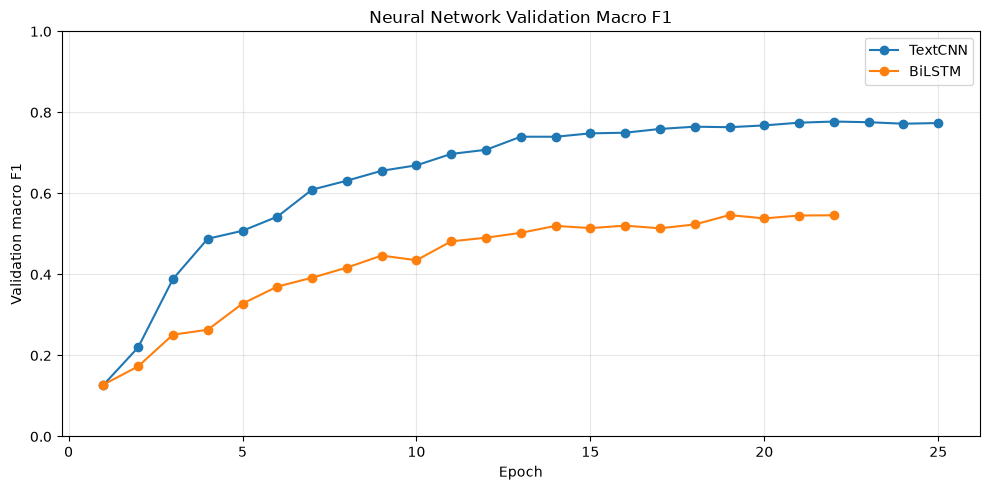

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    TEXTCNN_HISTORY["epoch"],
    TEXTCNN_HISTORY["validation_macro_f1"],
    marker="o",
    label="TextCNN",
)

ax.plot(
    BILSTM_HISTORY["epoch"],
    BILSTM_HISTORY["validation_macro_f1"],
    marker="o",
    label="BiLSTM",
)

ax.set(
    title="Neural Network Validation Macro F1",
    xlabel="Epoch",
    ylabel="Validation macro F1",
)

ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

### Interpreting Validation Macro F1

The learning curves provide a visual comparison of how quickly and consistently the two architectures improved on the validation data.

TextCNN shows a stronger upward trajectory and reaches a substantially higher validation macro F1. Its best result occurs at epoch 22, after which the curve shows small fluctuations rather than further improvement.

BiLSTM improves more gradually and remains below TextCNN throughout the recorded training history. Its best validation score occurs at epoch 19.

The difference between the curves supports the aggregate results: under the selected configurations, TextCNN learned a more effective representation for this classification task.

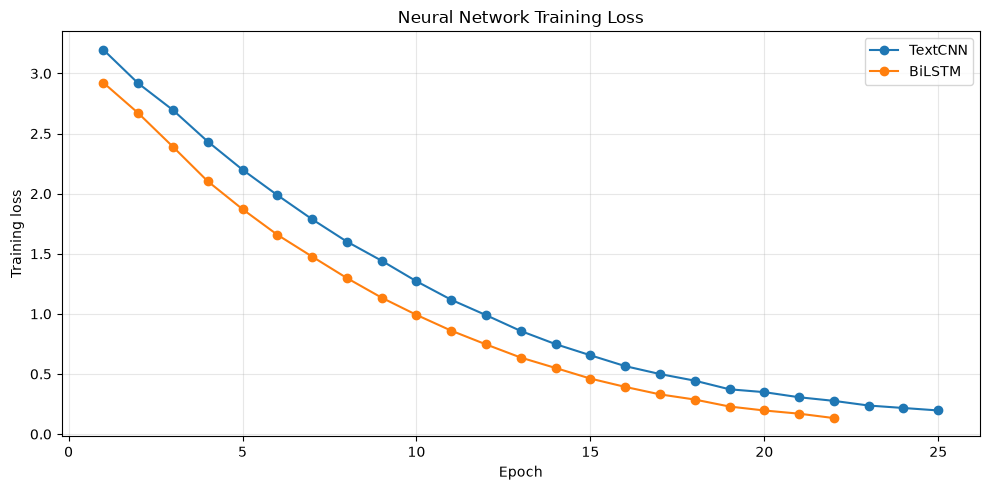

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    TEXTCNN_HISTORY["epoch"],
    TEXTCNN_HISTORY["training_loss"],
    marker="o",
    label="TextCNN",
)

ax.plot(
    BILSTM_HISTORY["epoch"],
    BILSTM_HISTORY["training_loss"],
    marker="o",
    label="BiLSTM",
)

ax.set(
    title="Neural Network Training Loss",
    xlabel="Epoch",
    ylabel="Training loss",
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

### Interpreting Training Loss

Both models show a consistent reduction in training loss, indicating that they progressively fitted the training documents.

The BiLSTM training loss continues to decrease even after its best validation result has been reached. TextCNN shows a similar pattern after its selected epoch.

When training loss continues to improve but validation performance does not, further fitting is not necessarily producing better generalisation. This reinforces the importance of selecting checkpoints using validation performance rather than simply choosing the final epoch.

The loss curves should therefore be interpreted together with the validation macro F1 curves, not as independent evidence of model quality.

## 9. Per-Class Validation Performance

Overall performance can conceal substantial differences in how well a model recognises individual topic categories.

The per-class results provide precision, recall, F1 and support for each category. Precision indicates how reliable the model's predictions are for a category, while recall indicates how many of the documents actually belonging to that category were correctly identified. F1 combines precision and recall into a single measure.

Support records the number of actual validation documents in each category. It provides useful context when comparing class-level results, particularly where categories have different numbers of validation examples.

Examining these results helps establish whether an architecture performs consistently across the dataset or achieves its overall score while struggling with particular categories.

In [11]:
def prepare_per_class_report(run: dict) -> pd.DataFrame:
    """Convert a neural run's per-class metrics into a labelled table."""
    report = pd.DataFrame(run["metrics"]["per_class"]).T

    report.index.name = "class_label"
    report = report.reset_index()

    report.insert(0, "model", run["model"])

    return report


TEXTCNN_PER_CLASS = prepare_per_class_report(TEXTCNN_RUN)
BILSTM_PER_CLASS = prepare_per_class_report(BILSTM_RUN)

NEURAL_PER_CLASS = pd.concat(
    [
        TEXTCNN_PER_CLASS,
        BILSTM_PER_CLASS,
    ],
    ignore_index=True,
)

display(
    NEURAL_PER_CLASS[
        [
            "model",
            "class_label",
            "precision",
            "recall",
            "f1_score",
            "support",
        ]
    ]
    .sort_values(
        ["model", "f1_score"],
        ascending=[True, True],
    )
    .reset_index(drop=True)
    .round(4)
)

,model,class_label,precision,recall,f1_score,support
0,BiLSTM,comp.sys.ibm.pc.hardware,0.3113,0.2797,0.2946,118.0
1,BiLSTM,sci.electronics,0.3540,0.3361,0.3448,119.0
2,BiLSTM,comp.graphics,0.3628,0.3534,0.3581,116.0
3,BiLSTM,rec.autos,0.3688,0.4958,0.4229,119.0
4,BiLSTM,comp.sys.mac.hardware,0.4048,0.4435,0.4232,115.0
5,BiLSTM,talk.religion.misc,0.4730,0.4605,0.4667,76.0
6,BiLSTM,sci.med,0.4224,0.5714,0.4857,119.0
7,BiLSTM,comp.windows.x,0.5591,0.4370,0.4906,119.0
8,BiLSTM,comp.os.ms-windows.misc,0.5182,0.4831,0.5000,118.0
9,BiLSTM,sci.space,0.6023,0.4492,0.5146,118.0


### Interpreting Per-Class Performance

The per-class results reveal differences that are not fully visible in the aggregate metrics.

TextCNN achieved its strongest F1 scores in `talk.politics.mideast` (0.9013), `rec.sport.hockey` (0.8980), `sci.crypt` (0.8816) and `rec.motorcycles` (0.8803).

Its weakest results occurred in `comp.sys.ibm.pc.hardware` (0.6025), `talk.religion.misc` (0.6241) and `comp.graphics` (0.6637).

BiLSTM also performed relatively well on `rec.sport.hockey` (0.7792) and `talk.politics.mideast` (0.7387). However, its weakest results were considerably lower, particularly for `comp.sys.ibm.pc.hardware` (0.2946), `sci.electronics` (0.3448) and `comp.graphics` (0.3581).

The comparison shows that TextCNN achieved stronger F1 scores across the reported topic categories. The computer-related categories appear particularly challenging for both models, although the difficulty is more pronounced for BiLSTM.

These differences may reflect overlapping vocabulary and subject matter between categories. The per-class scores identify where classification is difficult, but they do not establish the causes of individual errors. The detailed investigation of the selected model's misclassifications is reserved for Notebook 07.

## 10. Confusion Matrices

The confusion matrices provide a more detailed view of the models' classification decisions.

Rows represent the actual topic categories, while columns represent the categories predicted by the model. Values along the diagonal represent correctly classified documents. Values outside the diagonal show documents assigned to an incorrect category.

The two matrices are displayed separately so that the error patterns of TextCNN and BiLSTM can be examined independently.

These results are useful for identifying categories that the models may find difficult to distinguish. The matrices show where classification errors occur, but they do not explain why a particular document was misclassified.

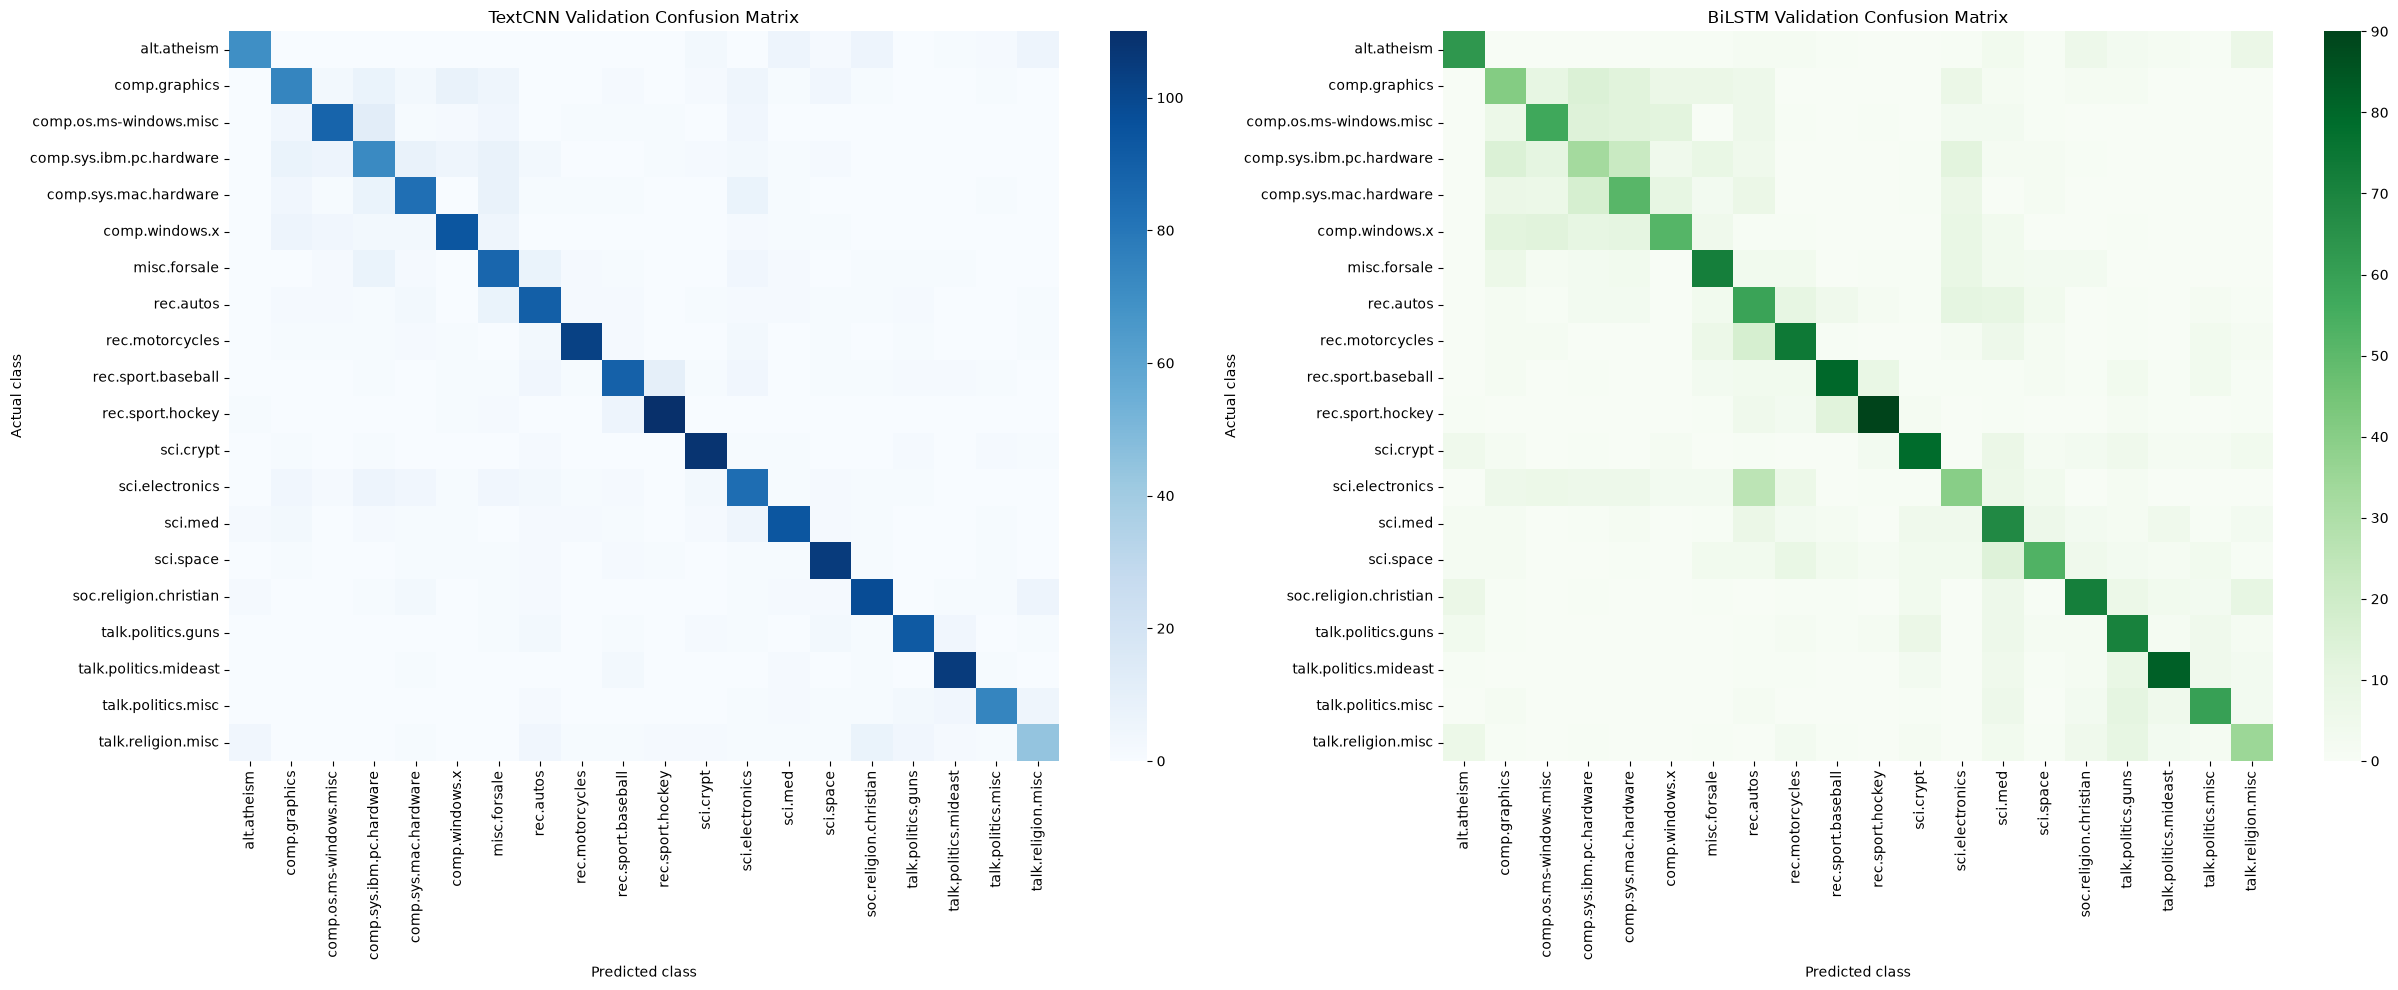

In [12]:
TEXTCNN_LABELS = TEXTCNN_RUN["metrics"]["class_labels"]
BILSTM_LABELS = BILSTM_RUN["metrics"]["class_labels"]

assert TEXTCNN_LABELS == BILSTM_LABELS

TEXTCNN_CONFUSION = pd.DataFrame(
    TEXTCNN_RUN["metrics"]["confusion_matrix"],
    index=TEXTCNN_LABELS,
    columns=TEXTCNN_LABELS,
)

BILSTM_CONFUSION = pd.DataFrame(
    BILSTM_RUN["metrics"]["confusion_matrix"],
    index=BILSTM_LABELS,
    columns=BILSTM_LABELS,
)

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(25, 10),
)

sns.heatmap(
    TEXTCNN_CONFUSION,
    cmap="Blues",
    ax=axes[0],
    xticklabels=True,
    yticklabels=True,
)

axes[0].set(
    title="TextCNN Validation Confusion Matrix",
    xlabel="Predicted class",
    ylabel="Actual class",
)

sns.heatmap(
    BILSTM_CONFUSION,
    cmap="Greens",
    ax=axes[1],
    xticklabels=True,
    yticklabels=True,
)

axes[1].set(
    title="BiLSTM Validation Confusion Matrix",
    xlabel="Predicted class",
    ylabel="Actual class",
)

for ax in axes:
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

### Interpreting the Confusion Matrices

The confusion matrices complement the per-class metrics by showing how documents are distributed across actual and predicted categories.

A strong diagonal indicates that a model correctly assigns many documents to their respective categories. Larger off-diagonal values identify categories that are more frequently confused.

The matrices should be examined alongside the per-class results. In particular, the weaker performance of both models on certain computer-related categories suggests that distinguishing between related technical topics may be difficult.

The matrices provide an overview of classification errors for these two neural architectures. Detailed directional confusion-pair analysis and examination of individual misclassified records are reserved for Notebook 07, where the selected model is investigated in greater depth.

## 11. Computational Performance

Classification quality is only one aspect of model evaluation. Computational requirements also matter, particularly when models must be trained or deployed in environments with limited resources.

The measurements below include fitting duration, validation prediction time, average prediction latency, throughput and serialised model artifact size.

Fitting duration includes the training process and repeated validation evaluations used for checkpoint selection. It is therefore the total experiment fitting time, not the duration of a single epoch.

Prediction measurements were collected on the validation partition using the configured batch size. They provide an indication of inference efficiency under the recorded experimental conditions, rather than a production-serving benchmark.

Artifact size represents the serialised model checkpoint payload, including the model parameters, vocabulary and associated metadata required to interpret the checkpoint.

Because both experiments use the same CPU environment and data partitions, their measurements provide a useful comparison of computational cost within this experimental setup.

In [13]:
NEURAL_EFFICIENCY = pd.DataFrame(
    [
        {
            "model": run["model"],
            "fit_seconds": run["fit_seconds"],
            "prediction_seconds": run["prediction_seconds"],
            "latency_ms_per_document": (run["latency_ms_per_document"]),
            "throughput_documents_per_second": (run["throughput_documents_per_second"]),
            "artifact_size_bytes": run["artifact_size_bytes"],
            "best_epoch": run["best_epoch"],
        }
        for run in NEURAL_RUNS
    ]
)

display(NEURAL_EFFICIENCY.sort_values("fit_seconds").reset_index(drop=True).round(4))

,model,fit_seconds,prediction_seconds,latency_ms_per_document,throughput_documents_per_second,artifact_size_bytes,best_epoch
0,TextCNN,422.9701,0.9310,0.4114,2430.6530,8472747,22
1,BiLSTM,6144.9233,2.0633,0.9117,1096.7999,8536928,19


### Interpreting Computational Performance

The computational measurements show a substantial difference in training cost between the two architectures.

TextCNN required approximately **423 seconds (7.05 minutes)** to complete training and validation, whereas BiLSTM required approximately **6,145 seconds (102.42 minutes)**. BiLSTM therefore took about 14.5 times as long to fit under the recorded conditions.

TextCNN also achieved higher validation throughput, processing approximately 2,431 documents per second compared with approximately 1,097 documents per second for BiLSTM. Its average prediction latency was also lower.

The serialised artifact sizes were similar, at approximately 8.47 MB for TextCNN and 8.54 MB for BiLSTM. The difference in training time is therefore not accompanied by a similarly large difference in the measured model artifact sizes.

Taken together, these measurements favour TextCNN in this experiment: it achieved stronger validation performance while requiring substantially less training time and providing higher validation inference throughput.

These measurements are specific to the CPU environment and evaluation procedure used here. They should not be treated as universal performance estimates or direct production-serving benchmarks.

## 12. Experiment Outputs and Reproducibility

Each experiment produces its own metrics CSV file and detailed JSON record. Keeping these outputs separate prevents one experiment from overwriting the results of the other.

The detailed records preserve the experiment identifier, model information, validation metrics, training history, configuration and computational measurements. Together, these outputs provide a record of how the reported results were obtained.

Model checkpoints are not persisted by default. This avoids retaining unnecessary large artifacts during baseline experiments. Checkpoint persistence can be enabled through the training configuration when a trained model needs to be retained for subsequent inference or deployment.

The final checks verify that both output pairs exist, that the saved records correspond to the expected experiments and that the official test partition was not used.

In [14]:
EXPERIMENT_OUTPUTS = [
    (
        "EXP-04",
        TEXTCNN_RESULTS,
        "TextCNN",
    ),
    (
        "EXP-05",
        BILSTM_RESULTS,
        "BiLSTM",
    ),
]

for experiment_id, results, model_name in EXPERIMENT_OUTPUTS:
    metrics_path = PROJECT_ROOT / results["metrics_csv"]
    results_path = PROJECT_ROOT / results["results_json"]

    assert metrics_path.is_file()
    assert results_path.is_file()

    with results_path.open("r", encoding="utf-8") as file:
        saved_results = json.load(file)

    assert saved_results["test_data_used"] is False
    assert len(saved_results["runs"]) == 1
    assert saved_results["runs"][0]["experiment_id"] == experiment_id
    assert saved_results["runs"][0]["model"] == model_name
    assert saved_results["runs"][0]["test_data_used"] is False

    print(f"{model_name}: output validation passed.")
    print(f"Metrics CSV: {metrics_path}")
    print(f"Detailed results: {results_path}")
    print(f"Test data used: {saved_results['test_data_used']}")
    print()

TextCNN: output validation passed.
Metrics CSV: /home/nkululekocyrilcele/projects/topicsense-nlp/results/metrics/neural_textcnn.csv
Detailed results: /home/nkululekocyrilcele/projects/topicsense-nlp/results/logs/neural_textcnn.json
Test data used: False

BiLSTM: output validation passed.
Metrics CSV: /home/nkululekocyrilcele/projects/topicsense-nlp/results/metrics/neural_bilstm.csv
Detailed results: /home/nkululekocyrilcele/projects/topicsense-nlp/results/logs/neural_bilstm.json
Test data used: False



### Interpreting the Output Checks

Both experiments passed the output validation checks.

The metrics CSV files and detailed JSON records exist at their expected locations. The saved records also contain the correct experiment identifiers and model names.

Most importantly, both the experiment-level and individual run records confirm that the official test partition was not used.

This establishes that the results reported in this notebook were produced using the intended development data and that the experiment outputs were saved successfully.

## 13. Experimental Findings, Conclusions and Limitations

The experiments establish neural-network baselines for supervised topic classification on the 20 Newsgroups dataset.

### 13.1 Comparative Performance

TextCNN achieved a validation macro F1 of **0.7774**, compared with **0.5465** for the Bidirectional LSTM. It also achieved higher accuracy, macro precision, macro recall and weighted F1.

Within the configurations evaluated, TextCNN therefore provides the stronger neural-network baseline.

### 13.2 Learning Behaviour

The training histories show that both models continued to reduce their training loss, but their validation performance stopped improving before the final completed epoch.

This supports the use of validation-based checkpoint selection and early stopping rather than automatically retaining the final training epoch.

### 13.3 Class-Level Performance

Neither architecture performs equally well across all 20 categories. TextCNN achieves stronger class-level results overall, although computer-related categories remain challenging.

The class-level results and confusion matrices identify areas of weaker classification performance. They do not, on their own, establish the underlying causes of individual errors.

### 13.4 Computational Requirements

TextCNN required substantially less training time and achieved higher validation throughput than BiLSTM. Their serialised artifact sizes were similar.

Under the recorded CPU conditions, TextCNN therefore offers a more favourable combination of predictive performance and computational cost.

### 13.5 Experimental Limitations

Several limitations should be considered when interpreting these findings:

- Both models use the same fixed training and validation split.
- The vocabulary is constructed exclusively from training documents.
- Documents are truncated or padded to a maximum sequence length of 256 tokens.
- Both architectures use the message-body representation.
- Word embeddings are learned from the available training data rather than obtained from an external pretrained embedding source.
- The experiments use bounded architecture configurations and do not represent exhaustive hyperparameter optimisation.
- Early stopping and checkpoint selection rely on validation macro F1.
- The official test partition has not been used, so these results do not establish final test performance.
- Runtime measurements reflect the recorded CPU environment and should not be generalised to other hardware without further benchmarking.
- Each experiment uses a single random seed, so the stability of the observed performance difference has not been established across repeated runs.

### 13.6 Conclusion and Transition

TextCNN is the stronger of the two neural-network baselines in these experiments. However, this finding does not establish that convolutional architectures are universally superior to recurrent networks, nor does it establish that either neural architecture is superior to the classical machine-learning baselines.

The subsequent transformer experiments investigate whether pretrained language representations offer further improvements in classification performance and whether those improvements justify their additional computational requirements.

The neural-network results will ultimately be considered alongside the classical and transformer experiments during the cross-family model-comparison stage in Notebook 06.